# V7 Alternative Split and Fused Preprocessing Contract

This notebook defines a second acquisition-level split for the V7 robustness experiment. It does not modify `data_split.json` or any V1-V6 preprocessing artifact. The split is selected before V7 training and without inspecting V7 performance.

## 1. Setup and authentication

In [1]:
%matplotlib inline

import getpass
import importlib
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import HfApi, hf_hub_download

SRC_DIR = Path.cwd() / 'src' if (Path.cwd() / 'src').exists() else Path.cwd()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
import preprocessing as preprocessing_module
preprocessing_module = importlib.reload(preprocessing_module)
from preprocessing import (
    PreprocessingConfig, normalize_per_radar_channel,
    per_radar_channel_moments, transform_fused_magnitude_iq,
)

HF_TOKEN = os.getenv('HF_TOKEN')
if not HF_TOKEN:
    HF_TOKEN = getpass.getpass('Enter your Hugging Face read-only token: ')
HF_TOKEN = HF_TOKEN.strip()
api = HfApi(token=HF_TOKEN)
print('Authenticated as:', api.whoami()['name'])
ARTIFACT_DIR = SRC_DIR / 'artifacts'
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
REPO_ID = 'HAEEAI/multi-person-localization'
TOTAL_WINDOWS = 24
SPLIT_SEED = 107

c:\Users\213053\OneDrive\Documenti\EEAI\.venv_tf\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Authenticated as: KetrinMehmeti


## 2. Resolve cached windows and measure occupancy

The occupancy class is read directly from each complete acquisition. Frame-level splitting is prohibited because adjacent radar frames are strongly correlated.

In [2]:
window_paths = {}
occupancy_by_window = {}
for index in range(TOTAL_WINDOWS):
    filename = f'data/window_{index:06d}.npz'
    window_paths[index] = Path(hf_hub_download(
        repo_id=REPO_ID, repo_type='dataset', filename=filename, token=HF_TOKEN
    ))
    with np.load(window_paths[index], allow_pickle=False) as data:
        frame_occupancy = data['people_mask'].astype(bool).sum(axis=1)
    unique_occupancy = np.unique(frame_occupancy)
    assert len(unique_occupancy) == 1
    occupancy_by_window[index] = int(unique_occupancy[0])
print('Occupancy by window:', occupancy_by_window)

Occupancy by window: {0: 2, 1: 2, 2: 2, 3: 2, 4: 2, 5: 4, 6: 4, 7: 4, 8: 4, 9: 4, 10: 4, 11: 4, 12: 3, 13: 3, 14: 3, 15: 3, 16: 1, 17: 1, 18: 1, 19: 1, 20: 1, 21: 1, 22: 0, 23: 0}


## 3. Define the predeclared alternative split

The primary validation windows are excluded from the candidate pool. One different complete window is then sampled for every occupancy class using the fixed seed 107. This produces a balanced, group-disjoint validation fold without selecting windows according to model accuracy. The empty-room class has only two recordings, so window 22 is necessarily the alternative to primary validation window 23.

In [3]:
with (ARTIFACT_DIR / 'data_split.json').open(encoding='utf-8') as handle:
    primary_split = json.load(handle)
PRIMARY_VALIDATION_WINDOWS = primary_split['validation_windows']
rng = np.random.default_rng(SPLIT_SEED)
candidate_groups = {people: [] for people in range(5)}
for index, people in occupancy_by_window.items():
    if index not in PRIMARY_VALIDATION_WINDOWS:
        candidate_groups[people].append(index)
V7_VALIDATION_WINDOWS = [
    int(rng.choice(candidate_groups[people])) for people in range(5)
]
V7_TRAIN_WINDOWS = [
    index for index in range(TOTAL_WINDOWS) if index not in V7_VALIDATION_WINDOWS
]
assert V7_VALIDATION_WINDOWS == [22, 16, 2, 15, 7]
assert set(V7_TRAIN_WINDOWS).isdisjoint(V7_VALIDATION_WINDOWS)
assert set(V7_VALIDATION_WINDOWS).isdisjoint(PRIMARY_VALIDATION_WINDOWS)
assert [occupancy_by_window[index] for index in V7_VALIDATION_WINDOWS] == list(range(5))
print('V7 training windows:', V7_TRAIN_WINDOWS)
print('V7 validation windows:', V7_VALIDATION_WINDOWS)
print('Validation occupancy:', [occupancy_by_window[i] for i in V7_VALIDATION_WINDOWS])

V7 training windows: [0, 1, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 17, 18, 19, 20, 21, 23]
V7 validation windows: [22, 16, 2, 15, 7]
Validation occupancy: [0, 1, 2, 3, 4]


## 4. Re-estimate fused statistics from V7 training windows

Changing the split also changes the permitted source of normalisation statistics. Reusing V6 statistics would leak information from four V7 validation windows, so V7 receives a separate fused preprocessing artifact.

In [4]:
V7_CONFIG = PreprocessingConfig(
    radar_indices=(0, 1, 2, 3, 4, 5), antenna_mode='none',
    range_bin_start=0, range_bin_stop=120,
    log_compression=True, background_mode='none',
)
V7_CHANNEL_ORDER = [
    'A0-mag', 'A1-mag', 'A2-mag',
    'A0-I', 'A0-Q', 'A1-I', 'A1-Q', 'A2-I', 'A2-Q',
]
CHUNK_SIZE = 256

def v7_training_feature_blocks():
    for position, index in enumerate(V7_TRAIN_WINDOWS, start=1):
        print(f'[{position:02d}/{len(V7_TRAIN_WINDOWS):02d}] Statistics from window {index:06d}')
        with np.load(window_paths[index], allow_pickle=False) as data:
            radar = data['radar_cir_iq']
            for start in range(0, len(radar), CHUNK_SIZE):
                yield transform_fused_magnitude_iq(
                    radar[start:start + CHUNK_SIZE], V7_CONFIG
                )

V7_MEAN, V7_STD, V7_VALUES_PER_CHANNEL = per_radar_channel_moments(
    v7_training_feature_blocks()
)
assert V7_MEAN.shape == V7_STD.shape == (6, 9)
assert np.all(V7_STD > 0)
print('Statistics shape:', V7_MEAN.shape)
print('Standard-deviation range:', float(V7_STD.min()), float(V7_STD.max()))

[01/19] Statistics from window 000000
[02/19] Statistics from window 000001
[03/19] Statistics from window 000003
[04/19] Statistics from window 000004
[05/19] Statistics from window 000005
[06/19] Statistics from window 000006
[07/19] Statistics from window 000008
[08/19] Statistics from window 000009
[09/19] Statistics from window 000010
[10/19] Statistics from window 000011
[11/19] Statistics from window 000012
[12/19] Statistics from window 000013
[13/19] Statistics from window 000014
[14/19] Statistics from window 000017
[15/19] Statistics from window 000018
[16/19] Statistics from window 000019
[17/19] Statistics from window 000020
[18/19] Statistics from window 000021
[19/19] Statistics from window 000023
Statistics shape: (6, 9)
Standard-deviation range: 1.4842414855957031 5.646330833435059


## 5. Validate the alternative contract

Window | occupancy | normalised mean | normalised std
    22 |         0 |          0.0015 |         0.9970
    16 |         1 |          0.0002 |         0.9991
     2 |         2 |          0.0103 |         1.0149
    15 |         3 |         -0.0165 |         0.9914
     7 |         4 |         -0.0006 |         0.9958


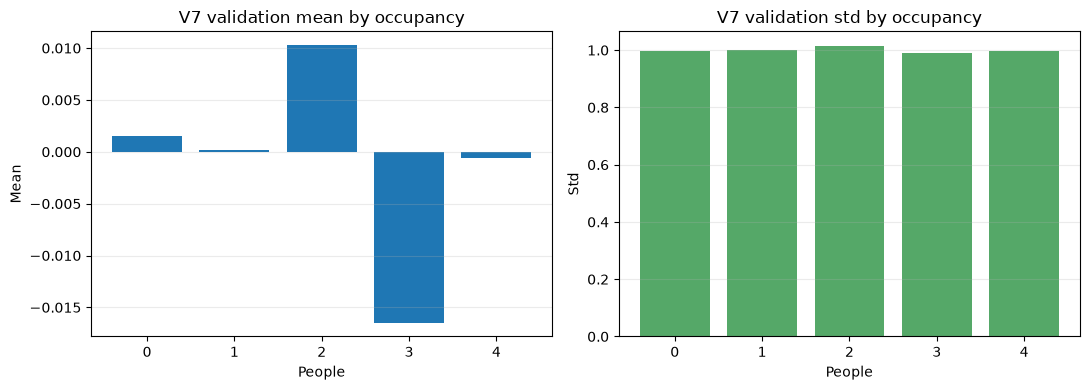

In [5]:
validation_summaries = []
for index in V7_VALIDATION_WINDOWS:
    with np.load(window_paths[index], allow_pickle=False) as data:
        features = transform_fused_magnitude_iq(data['radar_cir_iq'][:1024], V7_CONFIG)
    normalized = normalize_per_radar_channel(
        features, V7_MEAN, V7_STD, V7_CONFIG.epsilon
    )
    validation_summaries.append((index, normalized.mean(), normalized.std()))
print('Window | occupancy | normalised mean | normalised std')
for index, mean, std in validation_summaries:
    print(f'{index:>6} | {occupancy_by_window[index]:>9} | {mean:>15.4f} | {std:>14.4f}')
means = [row[1] for row in validation_summaries]
stds = [row[2] for row in validation_summaries]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(range(5), means)
axes[0].set(title='V7 validation mean by occupancy', xlabel='People', ylabel='Mean')
axes[1].bar(range(5), stds, color='#55a868')
axes[1].set(title='V7 validation std by occupancy', xlabel='People', ylabel='Std')
for axis in axes:
    axis.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Save separate V7 artifacts

In [6]:
v7_split = {
    'seed': SPLIT_SEED,
    'train_windows': V7_TRAIN_WINDOWS,
    'validation_windows': V7_VALIDATION_WINDOWS,
    'primary_validation_windows_excluded_from_sampling': PRIMARY_VALIDATION_WINDOWS,
    'validation_occupancy_order': list(range(5)),
    'rationale': 'Second predeclared group-stratified fold; one complete non-primary window per occupancy.',
}
v7_preprocessing = {
    'representation': 'fused_magnitude_signed_iq',
    'config': {
        'radar_indices': list(V7_CONFIG.radar_indices),
        'antenna_mode': V7_CONFIG.antenna_mode,
        'range_bin_start': V7_CONFIG.range_bin_start,
        'range_bin_stop': V7_CONFIG.range_bin_stop,
        'log_compression': V7_CONFIG.log_compression,
        'background_mode': V7_CONFIG.background_mode,
        'ema_alpha': V7_CONFIG.ema_alpha,
        'epsilon': V7_CONFIG.epsilon,
    },
    'channel_order': V7_CHANNEL_ORDER,
    'input_shape': [6, 9, 120],
    'mean': V7_MEAN.tolist(), 'std': V7_STD.tolist(),
    'statistics_source_windows': V7_TRAIN_WINDOWS,
    'validation_windows': V7_VALIDATION_WINDOWS,
}
split_path = ARTIFACT_DIR / 'data_split_v7.json'
stats_path = ARTIFACT_DIR / 'v7_fused_normalization.json'
with split_path.open('w', encoding='utf-8') as handle:
    json.dump(v7_split, handle, indent=2)
with stats_path.open('w', encoding='utf-8') as handle:
    json.dump(v7_preprocessing, handle, indent=2)
print('Saved:', split_path.resolve())
print('Saved:', stats_path.resolve())

Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\data_split_v7.json
Saved: C:\Users\213053\OneDrive\Documenti\EEAI\src\artifacts\v7_fused_normalization.json


## 7. Conclusions

V7 uses validation windows `[22, 16, 2, 15, 7]`, one complete recording for each occupancy level from zero to four people. These windows are disjoint from primary validation windows `[23, 18, 3, 14, 9]` and were selected with a fixed rule before V7 training. All other windows form the V7 training set.

This experiment measures split sensitivity; it does not search for an easier validation set. Because V6 and V7 are evaluated on different frames, their raw F1 values cannot by themselves establish that one architecture is better. The useful evidence is whether the same fused model remains competitive on a second unseen set of acquisition sessions.